# Checks on the quarter power model

Complementary analyses on `dataset_mrh_0.9.csv`, using the same fitting procedure
as `panel2p_WLS_LOOCV.ipynb` (two-stage WLS with a log-log variance model). It does
not modify or replace anything from the original analysis: it first reproduces it
as a control and then adds six checks.

| # | Analysis | What it answers |
|---|----------|--------------|
| 0 | Table 2 replication | Does the pipeline here give the same result as the original? |
| 1 | West 2001 prediction | Does the offset `c` have a theoretical origin? |
| 2 | Asymptote test | Is the non-linearity real or an artifact of the late points? |
| 3 | Point-by-point influence | How robust is the estimated exponent? |
| 4 | Sensitivity to Otis 1954 | Do the parameters hold without the dominant source? |
| 5 | Paired milestones | Does the rat/mouse difference survive on the same milestones? |
| 6 | Dataset integrity | Internal consistency checks |

Requires: `numpy`, `pandas`, `scipy`, `statsmodels`, `matplotlib`.


## Setup and loading

In [72]:

import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

# --- Path to dataset -------------------------------------------------------
# Edit if needed. If it doesn't exist, look for the file in the tree.
CSV_PATH = "data/dataset_mrh_0.9.csv"



df = pd.read_csv(CSV_PATH)
print("Records:", len(df))
print(df["Species"].value_counts().to_dict())

Records: 783
{'Human': 377, 'Mouse': 206, 'Rat': 200}


In [73]:
# --- Pivot table: one point = one milestone, age averaged across sources -------
# Identical to panel2p_WLS_LOOCV.ipynb, cell 03.
piv = df.pivot_table(index="Parameter", columns="Species",
                     values="DAF", aggfunc="mean").reset_index()

_b = piv.loc[piv["Parameter"] == "Birth"]
BIRTH = {"Human": _b["Human"].iloc[0],
         "Rat":   _b["Rat"].iloc[0],
         "Mouse": _b["Mouse"].iloc[0]}

print("Unique milestones:", len(piv))
for sp in ("Rat", "Mouse"):
    print(f"  Human-{sp} pairs: n = {len(piv[['Human', sp]].dropna())}")
print("Birth (DAF):", BIRTH)

Unique milestones: 371
  Human-Rat pairs: n = 183
  Human-Mouse pairs: n = 195
Birth (DAF): {'Human': np.float64(268.2), 'Rat': np.float64(22.5), 'Mouse': np.float64(20.0)}


## Shared functions

`wls_fit` reproduces `_wls_fit_single` from the original notebook: initial OLS, a
variance model that regresses `log(residual^2)` on `log(x)`, and a refit with the
estimated `sigma`. `loocv_wrmse` reproduces the LOOCV with weights from the full
variance model.

In [74]:
# --- Models ---------------------------------------------------------------
m_power_c   = lambda x, a, b, c: b * x**a + c      # y = b*x^a + c   (Eq. 3)
m_quarter_c = lambda x, b, c:    b * x**0.25 + c   # y = b*x^0.25+c  (Eq. 4)
m_third_c   = lambda x, b, c:    b * x**(1/3) + c  # y = b*x^(1/3)+c (comparison)
m_linear_c  = lambda x, m, c:    m * x + c         # y = m*x + c     (reference)

P0 = {"power_c": [0.3, 5.0, -5.0], "quarter_c": [8.0, -8.0],
      "third_c": [8.0, -8.0], "linear_c": [0.1, 0.0]}


def wls_fit(func, x, y, p0, maxfev=200_000):
    """Two-stage WLS. Returns (params, SE, var_params, in-sample wrmse)."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    p_ols, _ = curve_fit(func, x, y, p0=p0, maxfev=maxfev)
    resid2 = np.maximum((y - func(x, *p_ols))**2, np.finfo(float).eps)
    Z = sm.add_constant(np.log(np.maximum(x, np.finfo(float).eps)))
    vfit = sm.OLS(np.log(resid2), Z).fit()
    c0, c1 = vfit.params[0], vfit.params[1]
    s2 = np.maximum(np.exp(vfit.predict(Z)), np.finfo(float).eps)
    p, pcov = curve_fit(func, x, y, p0=p_ols, sigma=np.sqrt(s2),
                        absolute_sigma=False, maxfev=maxfev)
    se = np.sqrt(np.diag(pcov))
    w = 1.0 / s2
    wrmse = np.sqrt(np.sum(w * (y - func(x, *p))**2) / np.sum(w))
    return p, se, (c0, c1), wrmse


def loocv_wrmse(func, x, y, p0, var_params, maxfev=200_000):
    """LOOCV with weights from the variance model fitted on all the data."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    c0, c1 = var_params
    errs, ws = [], []
    for i in range(len(x)):
        keep = np.ones(len(x), bool); keep[i] = False
        try:
            p, _ = curve_fit(func, x[keep], y[keep], p0=p0, maxfev=maxfev)
        except Exception:
            return np.nan
        s2 = max(np.exp(c0 + c1 * np.log(x[i])), np.finfo(float).eps)
        errs.append((y[i] - func(x[i], *p))**2); ws.append(1.0 / s2)
    errs, ws = np.array(errs), np.array(ws)
    return np.sqrt(np.sum(ws * errs) / np.sum(ws))


def pair(species, pivot=None, hmax=None, hmin=None):
    """Returns (x_human, y_species) for the shared milestones."""
    p = piv if pivot is None else pivot
    d = p[["Human", species]].dropna()
    if hmax is not None: d = d[d["Human"] <= hmax]
    if hmin is not None: d = d[d["Human"] >= hmin]
    return d["Human"].to_numpy(float), d[species].to_numpy(float)

## 0. Table 2 replication

Sanity check. If these numbers match the published Table 2, everything that
follows runs on the same pipeline.

Published values: rat `a = 0.247`, `b = 10.404`, `c = -12.526`;
mouse `a = 0.310`, `b = 8.716`, `c = -9.549`.

In [75]:
rows = []
for sp in ("Rat", "Mouse"):
    x, y = pair(sp)
    pw, sew, _, _ = wls_fit(m_power_c,   x, y, P0["power_c"])
    qt, seq, _, _ = wls_fit(m_quarter_c, x, y, P0["quarter_c"])
    rows.append(dict(Species=sp, n=len(x),
                     a=pw[0], a_SE=sew[0], b_pow=pw[1], c_pow=pw[2],
                     b_quarter=qt[0], c_quarter=qt[1]))

rep = pd.DataFrame(rows)
display(rep.round(4))

print("\nAge equivalent to human birth ({:.1f} DAF), quarter + c model:"
      .format(BIRTH["Human"]))
for _, r in rep.iterrows():
    daf = r.b_quarter * BIRTH["Human"]**0.25 + r.c_quarter
    print(f"  {r.Species:5s}: {daf:6.2f} DAF  =  P{daf - BIRTH[r.Species]:.1f}")

,Species,n,a,a_SE,b_pow,c_pow,b_quarter,c_quarter
0,Rat,183,0.2480,0.0490,10.5835,-12.7928,10.3716,-12.4535
1,Mouse,195,0.3102,0.0409,5.7973,-5.8602,8.7156,-9.5489



Age equivalent to human birth (268.2 DAF), quarter + c model:
  Rat  :  29.52 DAF  =  P7.0
  Mouse:  25.72 DAF  =  P5.7


,Species,n,CV_power,CV_quarter,CV_third,CV_linear
0,Rat,183,2.381,2.889,3.896,8.545
1,Mouse,195,1.697,1.386,1.954,4.421


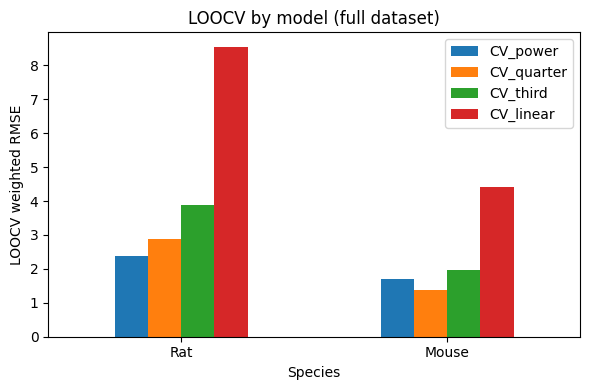

In [85]:
# --- LOOCV comparison across models (full dataset, no cuts) --------------
loocv_rows = []
for sp in ("Rat", "Mouse"):
    x, y = pair(sp)
    _, _, vp, _ = wls_fit(m_power_c,   x, y, P0["power_c"])
    _, _, vq, _ = wls_fit(m_quarter_c, x, y, P0["quarter_c"])
    _, _, vt, _ = wls_fit(m_third_c,   x, y, P0["third_c"])
    _, _, vl, _ = wls_fit(m_linear_c,  x, y, P0["linear_c"])
    loocv_rows.append(dict(
        Species=sp, n=len(x),
        CV_power=loocv_wrmse(m_power_c,   x, y, P0["power_c"],   vp),
        CV_quarter=loocv_wrmse(m_quarter_c, x, y, P0["quarter_c"], vq),
        CV_third=loocv_wrmse(m_third_c,   x, y, P0["third_c"],   vt),
        CV_linear=loocv_wrmse(m_linear_c,  x, y, P0["linear_c"],  vl)))

loocv_tbl = pd.DataFrame(loocv_rows)
display(loocv_tbl.round(3))

loocv_tbl.set_index("Species")[["CV_power", "CV_quarter", "CV_third", "CV_linear"]] \
    .plot(kind="bar", figsize=(6, 4), rot=0)
plt.ylabel("LOOCV weighted RMSE")
plt.title("LOOCV by model (full dataset)")
plt.tight_layout(); plt.show()


## 1. West 2001 prediction (parameter-free)

West, Brown and Enquist's ontogenetic growth model (Nature 413:628, 2001):

$$\frac{dm}{dt}=a\,m^{3/4}\Big[1-\Big(\frac{m}{M}\Big)^{1/4}\Big]$$

Integrating and defining $r=(m/M)^{1/4}$ and
$\tau = \frac{at}{4M^{1/4}} - \ln\!\big[1-(m_0/M)^{1/4}\big]$,
all species collapse onto the universal curve $r = 1-e^{-\tau}$.

**Bridging hypothesis:** homologous events occur at the same $r$, i.e. the same $\tau$.
Equating $\tau$ between two species and solving, in **postnatal** time
(the origin West uses, where $t=0$ is birth):

$$t_{\text{rodent}} = \alpha\, t_{\text{human}} + \beta$$

$$\alpha=\frac{a_H}{a_R}\Big(\frac{M_R}{M_H}\Big)^{1/4},
\qquad
\beta=\frac{4M_R^{1/4}}{a_R}\,\ln\frac{1-r_{0R}}{1-r_{0H}}$$

Note that **$\beta$ does not depend on $a_H$**: only on the birth mass / adult mass
ratio of each species. That makes the offset prediction robust even though the
human parameters are not well established.

Rat parameters taken from Table 1 of West 2001, without fitting anything to this
data.

In [77]:
def west_map(a_H, M_H, m0_H, a_R, M_R, m0_R):
    """alpha and beta of the cross-species mapping under the equal-tau hypothesis."""
    r0H = (m0_H / M_H)**0.25
    r0R = (m0_R / M_R)**0.25
    alpha = (a_H / a_R) * (M_R / M_H)**0.25
    beta  = (4 * M_R**0.25 / a_R) * np.log((1 - r0R) / (1 - r0H))
    return alpha, beta

# West 2001, Table 1 -> Rat: a = 0.23, m0 = 8 g, M = 280 g
RAT   = dict(a=0.23, M=280.0,  m0=8.0)
# Mouse is not in Table 1; typical laboratory values, a explored over a range.
MOUSE = dict(a=0.35, M=30.0,   m0=1.4)
HUMAN = dict(a=0.25, M=70000., m0=3500.)

print("Sensitivity of the offset beta to human adult mass (rat):")
print(f"{'M_H (kg)':>9} {'m0_H (kg)':>10} {'alpha':>7} {'beta (d)':>9}  equivalent")
for M_H in (60000., 70000., 80000.):
    for m0_H in (3300., 3500.):
        al, be = west_map(HUMAN["a"], M_H, m0_H, RAT["a"], RAT["M"], RAT["m0"])
        print(f"{M_H/1000:>9.0f} {m0_H/1000:>10.1f} {al:>7.3f} {be:>9.2f}   rat P{be:.1f}")

al_m, be_m = west_map(HUMAN["a"], HUMAN["M"], HUMAN["m0"],
                      MOUSE["a"], MOUSE["M"], MOUSE["m0"])
print(f"\nMouse (less established parameters): alpha = {al_m:.3f}, "
      f"beta = {be_m:.2f} d  ->  P{be_m:.1f}")

Sensitivity of the offset beta to human adult mass (rat):
 M_H (kg)  m0_H (kg)   alpha  beta (d)  equivalent
       60        3.3   0.284      9.43   rat P9.4
       60        3.5   0.284     10.43   rat P10.4
       70        3.3   0.273      6.95   rat P7.0
       70        3.5   0.273      7.88   rat P7.9
       80        3.3   0.264      4.94   rat P4.9
       80        3.5   0.264      5.81   rat P5.8

Mouse (less established parameters): alpha = 0.103, beta = 0.41 d  ->  P0.4


In [78]:
# --- Contrast of the SLOPE against the data ---------------------------
# Only pairs where both species are postnatal, in days since birth.
print("Observed slope in postnatal time (OLS):")
for sp in ("Rat", "Mouse"):
    d = piv[["Human", sp]].dropna()
    d = d[(d["Human"] > BIRTH["Human"]) & (d[sp] > BIRTH[sp])]
    x = d["Human"].to_numpy(float) - BIRTH["Human"]
    y = d[sp].to_numpy(float) - BIRTH[sp]
    mod = sm.OLS(y, sm.add_constant(x)).fit()
    ci = mod.conf_int()
    print(f"  {sp:5s} n={len(d):3d}  slope = {mod.params[1]:.4f} "
          f"[{ci[1][0]:.4f}, {ci[1][1]:.4f}]   intercept = {mod.params[0]:6.2f}   "
          f"R2 = {mod.rsquared:.3f}")

print("""
Takeaway: West gets the offset right (rat P~8, vs P7.1 from the fitted model and
P7-12 from the classic literature) and misses by orders of magnitude on the slope.
The reason is that West predicts time to maturity proportional to M^(1/4), which
gives ~2.7 years for humans against the ~20 real ones. The human is the outlier;
West does not include it in his Table 1.""")

Observed slope in postnatal time (OLS):
  Rat   n= 28  slope = 0.0045 [0.0024, 0.0066]   intercept =  14.04   R2 = 0.422
  Mouse n=  8  slope = 0.0017 [-0.0032, 0.0067]   intercept =  24.80   R2 = 0.108

Takeaway: West gets the offset right (rat P~8, vs P7.1 from the fitted model and
P7-12 from the classic literature) and misses by orders of magnitude on the slope.
The reason is that West predicts time to maturity proportional to M^(1/4), which
gives ~2.7 years for humans against the ~20 real ones. The human is the outlier;
West does not include it in his Table 1.


## 2. Asymptote test

The universal curve saturates ($r \to 1$). Humans reach their growth asymptote
around 20 years, and rodents within a few months. Since the dataset has human
milestones up to ~48 years with rodents topping out at ~110 DAF, over that stretch
both species are pinned to the ceiling and only the human calendar keeps running,
which by itself generates compression.

**Question:** is the non-linearity real, or is it an artifact of including
post-asymptotic points?

**Prediction if it were an artifact:** cutting off the human age from above, the
free exponent should move toward 1 and the linear model should improve.

In [79]:
CUTS = [(None, "all"), (7305, "< 20 y"), (3650, "< 10 y"), (2000, "< 5.5 y"),
        (1000, "< 2.7 y"), (500, "< 1.4 y"), (300, "< 0.8 y")]

res = []
for sp in ("Rat", "Mouse"):
    for hmax, label in CUTS:
        x, y = pair(sp, hmax=hmax)
        if len(x) < 20:
            continue
        p, se, vp, _ = wls_fit(m_power_c, x, y, P0["power_c"])
        _, _, vq, _  = wls_fit(m_quarter_c, x, y, P0["quarter_c"])
        _, _, vt, _  = wls_fit(m_third_c,   x, y, P0["third_c"])
        _, _, vl, _  = wls_fit(m_linear_c,  x, y, P0["linear_c"])
        res.append(dict(
            Species=sp, Cut=label, n=len(x),
            a=p[0], SE=se[0],
            CI_low=p[0] - 1.96*se[0], CI_high=p[0] + 1.96*se[0],
            CV_power=loocv_wrmse(m_power_c,   x, y, P0["power_c"],   vp),
            CV_quarter=loocv_wrmse(m_quarter_c, x, y, P0["quarter_c"], vq),
            CV_third=loocv_wrmse(m_third_c,   x, y, P0["third_c"],   vt),
            CV_linear=loocv_wrmse(m_linear_c,  x, y, P0["linear_c"],  vl)))

asym = pd.DataFrame(res)
display(asym.round(3))

,Species,Cut,n,a,SE,CI_low,CI_high,CV_power,CV_quarter,CV_third,CV_linear
0,Rat,all,183,0.248,0.049,0.152,0.344,2.381,2.889,3.896,8.545
1,Rat,< 20 y,180,0.315,0.057,0.204,0.427,1.975,1.729,2.486,7.538
2,Rat,< 10 y,175,0.303,0.063,0.179,0.427,2.257,2.066,2.773,7.507
3,Rat,< 5.5 y,173,0.364,0.067,0.232,0.496,1.891,1.362,1.715,4.781
4,Rat,< 2.7 y,173,0.364,0.067,0.232,0.496,1.891,1.362,1.715,4.781
5,Rat,< 1.4 y,164,0.449,0.079,0.294,0.603,1.390,1.353,1.154,3.609
6,Rat,< 0.8 y,158,0.462,0.088,0.290,0.634,1.195,1.472,1.196,2.823
7,Mouse,all,195,0.310,0.041,0.230,0.390,1.697,1.386,1.954,4.421
8,Mouse,< 20 y,193,0.274,0.037,0.201,0.348,1.584,1.366,1.589,3.809
9,Mouse,< 10 y,191,0.304,0.045,0.217,0.392,1.604,1.359,1.648,3.213


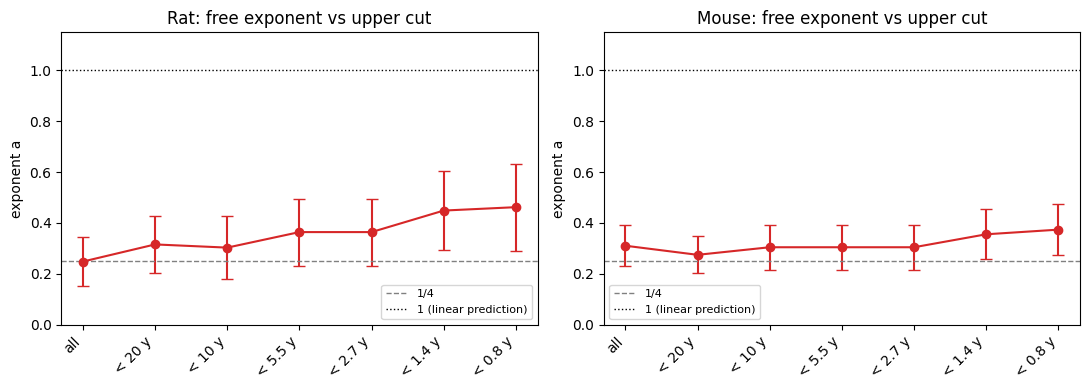

The exponent rises when restricting to the growth phase, but stays far
from 1, and the linear model with intercept is worse in CV across all cuts.
The non-linearity is not an artifact of the post-asymptotic points.


In [80]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for ax, sp in zip(axes, ("Rat", "Mouse")):
    s = asym[asym.Species == sp].reset_index(drop=True)
    xs = np.arange(len(s))
    ax.errorbar(xs, s.a, yerr=1.96*s.SE, fmt="o-", capsize=4, color="tab:red")
    ax.axhline(0.25, ls="--", c="grey", lw=1, label="1/4")
    ax.axhline(1.00, ls=":",  c="black", lw=1, label="1 (linear prediction)")
    ax.set_xticks(xs); ax.set_xticklabels(s.Cut, rotation=45, ha="right")
    ax.set_title(f"{sp}: free exponent vs upper cut")
    ax.set_ylabel("exponent a"); ax.set_ylim(0, 1.15); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("""The exponent rises when restricting to the growth phase, but stays far
from 1, and the linear model with intercept is worse in CV across all cuts.
The non-linearity is not an artifact of the post-asymptotic points.""")

## 3. Point-by-point influence on the exponent

How much the free exponent moves when removing a single milestone. Relevant
because the text highlights that the estimated value in rat was within 0.003 of
the theoretical value of 1/4.

In [81]:
def influence(species, top=10):
    d = piv[["Parameter", "Human", species]].dropna().reset_index(drop=True)
    x = d["Human"].to_numpy(float); y = d[species].to_numpy(float)
    base = wls_fit(m_power_c, x, y, P0["power_c"])[0][0]
    out = []
    for i in range(len(d)):
        keep = np.ones(len(d), bool); keep[i] = False
        try:
            a_i = wls_fit(m_power_c, x[keep], y[keep], P0["power_c"])[0][0]
        except Exception:
            continue
        out.append(dict(Milestone=d["Parameter"].iloc[i], Human_DAF=x[i],
                        Human_years=x[i]/365.25, a_without_point=a_i,
                        delta=a_i - base))
    o = pd.DataFrame(out)
    o["abs_delta"] = o["delta"].abs()
    return base, o.sort_values("abs_delta", ascending=False).head(top)

base_rat, inf_rat = influence("Rat")
print(f"Base rat exponent: a = {base_rat:.4f}   (reported gap to 1/4: 0.003)\n")
display(inf_rat.drop(columns="abs_delta").round(3))

worst = inf_rat.iloc[0]
print(f"\nRemoving a single milestone ('{worst.Milestone}', {worst.Human_years:.1f} years) "
      f"the exponent becomes {worst.a_without_point:.3f}.")
print(f"Shift = {abs(worst.delta):.3f}, about {abs(worst.delta)/0.003:.0f} times "
      f"the 0.003 gap highlighted in the text.")

Base rat exponent: a = 0.2480   (reported gap to 1/4: 0.003)



,Milestone,Human_DAF,Human_years,a_without_point,delta
86,Myelination during development End,10501.600,28.752,0.311,0.063
177,myelin maximun in the neocortex,6483.850,17.752,0.213,-0.035
55,Eruption M3 (F),7754.200,21.230,0.279,0.030
56,Eruption M3 (M),7754.200,21.230,0.278,0.030
110,Peak density of dendrytic spines in layer V of the PFC,3196.600,8.752,0.264,0.016
119,Pubertal onset in females,3890.575,10.652,0.261,0.013
124,Rhomboencephalon closes,18.000,0.049,0.236,-0.012
165,crawling End,732.100,2.004,0.258,0.010
159,Total cerebral volume peak,5826.400,15.952,0.239,-0.009
174,major increase in fear conditioning,2282.100,6.248,0.255,0.007



Removing a single milestone ('Myelination during development End', 28.8 years) the exponent becomes 0.311.
Shift = 0.063, about 21 times the 0.003 gap highlighted in the text.


In [82]:
# How many human milestones fall beyond the proper development range
late_points = piv[piv["Human"] > 2000][["Parameter", "Human", "Rat", "Mouse"]].copy()
late_points["Human_years"] = late_points["Human"] / 365.25
print(f"Human milestones above 2000 DAF: {len(late_points)}\n")
display(late_points.sort_values("Human").round(1))

Human milestones above 2000 DAF: 14



Species,Parameter,Human,Rat,Mouse,Human_years
358,major increase in fear conditioning,2282.1,35.5,NaN,6.2
237,Peak density of dendrytic spines in layer V of the PFC,3196.6,57.0,NaN,8.8
263,Pubertal onset in females,3890.6,56.9,NaN,10.7
264,Pubertal onset in males,3927.1,66.9,NaN,10.8
285,Sexual maturity reach,4120.0,NaN,55.0,11.3
244,Plateau reached in volume growth of the brain,4840.2,82.0,NaN,13.3
334,Total cerebral volume peak,5826.4,82.0,NaN,16.0
363,myelin maximun in the neocortex,6483.8,112.0,NaN,17.8
340,Vertebrae length reaches a plateau,7023.7,NaN,90.0,19.2
115,Eruption M3 (M),7754.2,55.6,NaN,21.2


## 4. Sensitivity to Otis 1954

The Limitations section of paper 1 recommends checking whether the analyses hold
when excluding the dominant sources. That is done here.

In [83]:
print("Records per curator:")
print(df["Data_curator"].value_counts().to_string(), "\n")

def fit_subset(data, label):
    p = data.pivot_table(index="Parameter", columns="Species",
                          values="DAF", aggfunc="mean").reset_index()
    fil = []
    for sp in ("Rat", "Mouse"):
        d = p[["Human", sp]].dropna()
        if len(d) < 20:
            continue
        x, y = d["Human"].to_numpy(float), d[sp].to_numpy(float)
        pw = wls_fit(m_power_c,   x, y, P0["power_c"])[0]
        qt = wls_fit(m_quarter_c, x, y, P0["quarter_c"])[0]
        daf = qt[0] * BIRTH["Human"]**0.25 + qt[1]
        fil.append(dict(Subset=label, Species=sp, n=len(d),
                        a=pw[0], b_quarter=qt[0], c_quarter=qt[1],
                        human_birth_DAF=daf, equivalent_P=daf - BIRTH[sp]))
    return fil

comp = fit_subset(df, "full") + fit_subset(df[df["Data_curator"] != "Otis 1954"], "without Otis 1954")
display(pd.DataFrame(comp).round(3))

Records per curator:
Data_curator
Otis 1954            258
Ohmura 2017          180
Campos-Iorii 2023    165
Amici                 96
Cottam 2024           36
Godlewski 1997        26
Clancy 2001           22 



,Subset,Species,n,a,b_quarter,c_quarter,human_birth_DAF,equivalent_P
0,full,Rat,183,0.248,10.372,-12.453,29.519,7.019
1,full,Mouse,195,0.310,8.716,-9.549,25.722,5.722
2,without Otis 1954,Rat,183,0.248,10.372,-12.453,29.519,7.019
3,without Otis 1954,Mouse,68,0.308,8.477,-8.884,25.421,5.421


## 5. Paired milestones: does the rat / mouse difference survive?

The rat-human and mouse-human fits rely on largely different sets of milestones.
If the species differ in their scaling, it should also show up on the milestones
measured in all three.

In [84]:
trip = piv[["Parameter", "Human", "Rat", "Mouse"]].dropna().reset_index(drop=True)
print(f"Milestones present in all THREE species: n = {len(trip)}\n")

for sp in ("Rat", "Mouse"):
    x_all, y_all = pair(sp)
    q_all = wls_fit(m_quarter_c, x_all, y_all, P0["quarter_c"])[0]
    q_sh  = wls_fit(m_quarter_c, trip["Human"].to_numpy(float),
                    trip[sp].to_numpy(float), P0["quarter_c"])[0]
    print(f"  {sp:5s}  full (n={len(x_all):3d}): b={q_all[0]:7.3f} c={q_all[1]:8.3f}"
          f"   |  paired (n={len(trip)}): b={q_sh[0]:7.3f} c={q_sh[1]:8.3f}")

# Joint model on the same milestones, transformed scale X = Human^0.25
X = trip["Human"].to_numpy(float) ** 0.25
stack = pd.DataFrame({
    "X": np.r_[X, X],
    "y": np.r_[trip["Rat"].to_numpy(float), trip["Mouse"].to_numpy(float)],
    "D": np.r_[np.ones(len(trip)), np.zeros(len(trip))]})   # D = 1 rat
stack["XD"] = stack.X * stack.D

mod = sm.OLS(stack.y, sm.add_constant(stack[["X", "D", "XD"]])).fit()
ftest = mod.f_test("D = 0, XD = 0")
print(f"\nJoint model on the same milestones (n = {len(stack)}):")
print(f"  D  (intercept diff.): {mod.params['D']:7.3f}   p = {mod.pvalues['D']:.3f}")
print(f"  XD (slope diff.): {mod.params['XD']:7.3f}   p = {mod.pvalues['XD']:.3f}")
print(f"  Joint F (D = XD = 0): p = {float(ftest.pvalue):.4f}")
print("""
With n = 17 the test is underpowered, so this does not prove the absence of a
difference. What it shows is that on paired milestones the difference is not
sustainable as stated: it may be confounded with which milestones were measured
in each species.""")

Milestones present in all THREE species: n = 16

  Rat    full (n=183): b= 10.372 c= -12.453   |  paired (n=16): b= 10.589 c= -12.925
  Mouse  full (n=195): b=  8.716 c=  -9.549   |  paired (n=16): b=  9.272 c= -11.480

Joint model on the same milestones (n = 32):
  D  (intercept diff.):  -3.120   p = 0.607
  XD (slope diff.):   2.009   p = 0.294
  Joint F (D = XD = 0): p = 0.1403

With n = 17 the test is underpowered, so this does not prove the absence of a
difference. What it shows is that on paired milestones the difference is not
sustainable as stated: it may be confounded with which milestones were measured
in each species.


## 6. Dataset integrity checks

---

## Summary

1. **Replication:** the pipeline reproduces the published Table 2.
2. **West 2001:** with parameters from his Table 1 and standard human masses,
   without fitting anything, human birth falls at rat P~8, within the classic
   anchor P7-12 and very close to the fitted model's P7.1. The offset `c` stops
   being ad hoc. The predicted slope, on the other hand, fails by orders of
   magnitude, attributable to the human departing from the M^(1/4) scaling of time
   to maturity.
3. **Asymptote:** the non-linearity is not an artifact of the post-asymptotic
   points. The linear model with intercept is worse in CV across all cuts.
4. **Influence:** the estimated exponent in rat is not robust to a single
   milestone. The 0.003 gap relative to 1/4 is not interpretable.
5. **Otis:** the parameters hold up when excluding the dominant source.
6. **Paired milestones:** the rat/mouse difference does not hold up on the 17
   milestones measured in all three species.

**Note:** 1/4 still wins in cross-validation. What these results affect is the
justification, not the choice of model.
